## Project Overview

This project applies **unsupervised machine learning** to identify distinct customer segments based on demographic and behavioral characteristics. Using the **AZDIAS demographic dataset** and customer data from Arvato Financial Solutions, the goal is to understand how a company's existing customers differ from the general population and identify potential target groups for marketing campaigns.

The analysis involves data cleaning, feature engineering, dimensionality reduction using **Principal Component Analysis (PCA)**, and **K-Means clustering** to group individuals with similar characteristics.

By comparing the distribution of clusters between the general population and the customer base, the project identifies customer segments that are overrepresented or underrepresented. These findings can help businesses better understand their target audience, improve marketing strategies, and make data-driven decisions about customer acquisition.


In [1]:
import sklearn
print('The scikit-learn version is {}.'.format(sklearn.__version__))

The scikit-learn version is 0.24.2.


In [2]:
import os

os.environ['PATH'] = os.environ['PATH'] + ':/root/.local/bin'

In [3]:
!python -m pip install --upgrade scikit-learn
import sklearn
print('The scikit-learn version is {}.'.format(sklearn.__version__))

Requirement already up-to-date: scikit-learn in /opt/conda/lib/python3.6/site-packages (0.24.2)
The scikit-learn version is 0.24.2.


In [4]:
from sklearn.preprocessing import OneHotEncoder


In [5]:
!python -m pip install 'tensorflow-tensorboard<0.2.0,>=0.1.0'

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


%matplotlib inline


pd.options.display.max_rows = None
pd.options.display.max_columns = None

In [7]:

azdias_raw = pd.read_csv('Udacity_AZDIAS_Subset.csv', sep=';')
azdias = azdias_raw.copy()


feat_info = pd.read_csv('AZDIAS_Feature_Summary.csv', sep=';')


In [8]:
print('AZDIAS shape:', azdias.shape)
print('Feature summary shape:', feat_info.shape)
display(azdias.head())
display(feat_info.head())


AZDIAS shape: (891221, 85)
Feature summary shape: (85, 4)


,AGER_TYP,ALTERSKATEGORIE_GROB,ANREDE_KZ,CJT_GESAMTTYP,FINANZ_MINIMALIST,FINANZ_SPARER,FINANZ_VORSORGER,FINANZ_ANLEGER,FINANZ_UNAUFFAELLIGER,FINANZ_HAUSBAUER,FINANZTYP,GEBURTSJAHR,GFK_URLAUBERTYP,GREEN_AVANTGARDE,HEALTH_TYP,LP_LEBENSPHASE_FEIN,LP_LEBENSPHASE_GROB,LP_FAMILIE_FEIN,LP_FAMILIE_GROB,LP_STATUS_FEIN,LP_STATUS_GROB,NATIONALITAET_KZ,PRAEGENDE_JUGENDJAHRE,RETOURTYP_BK_S,SEMIO_SOZ,SEMIO_FAM,SEMIO_REL,SEMIO_MAT,SEMIO_VERT,SEMIO_LUST,SEMIO_ERL,SEMIO_KULT,SEMIO_RAT,SEMIO_KRIT,SEMIO_DOM,SEMIO_KAEM,SEMIO_PFLICHT,SEMIO_TRADV,SHOPPER_TYP,SOHO_KZ,TITEL_KZ,VERS_TYP,ZABEOTYP,ALTER_HH,ANZ_PERSONEN,ANZ_TITEL,HH_EINKOMMEN_SCORE,KK_KUNDENTYP,W_KEIT_KIND_HH,WOHNDAUER_2008,ANZ_HAUSHALTE_AKTIV,ANZ_HH_TITEL,GEBAEUDETYP,KONSUMNAEHE,MIN_GEBAEUDEJAHR,OST_WEST_KZ,WOHNLAGE,CAMEO_DEUG_2015,CAMEO_DEU_2015,CAMEO_INTL_2015,KBA05_ANTG1,KBA05_ANTG2,KBA05_ANTG3,KBA05_ANTG4,KBA05_BAUMAX,KBA05_GBZ,BALLRAUM,EWDICHTE,INNENSTADT,GEBAEUDETYP_RASTER,KKK,MOBI_REGIO,ONLINE_AFFINITAET,REGIOTYP,KBA13_ANZAHL_PKW,PLZ8_ANTG1,PLZ8_ANTG2,PLZ8_ANTG3,PLZ8_ANTG4,PLZ8_BAUMAX,PLZ8_HHZ,PLZ8_GBZ,ARBEIT,ORTSGR_KLS9,RELAT_AB
0,-1,2,1,2.0,3,4,3,5,5,3,4,0,10.0,0,-1,15.0,4.0,2.0,2.0,1.0,1.0,0,0,5.0,2,6,7,5,1,5,3,3,4,7,6,6,5,3,-1,NaN,NaN,-1,3,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,-1,1,2,5.0,1,5,2,5,4,5,1,1996,10.0,0,3,21.0,6.0,5.0,3.0,2.0,1.0,1,14,1.0,5,4,4,3,1,2,2,3,6,4,7,4,7,6,3,1.0,0.0,2,5,0.0,2.0,0.0,6.0,NaN,3.0,9.0,11.0,0.0,8.0,1.0,1992.0,W,4.0,8,8A,51,0.0,0.0,0.0,2.0,5.0,1.0,6.0,3.0,8.0,3.0,2.0,1.0,3.0,3.0,963.0,2.0,3.0,2.0,1.0,1.0,5.0,4.0,3.0,5.0,4.0
2,-1,3,2,3.0,1,4,1,2,3,5,1,1979,10.0,1,3,3.0,1.0,1.0,1.0,3.0,2.0,1,15,3.0,4,1,3,3,4,4,6,3,4,7,7,7,3,3,2,0.0,0.0,1,5,17.0,1.0,0.0,4.0,NaN,3.0,9.0,10.0,0.0,1.0,5.0,1992.0,W,2.0,4,4C,24,1.0,3.0,1.0,0.0,0.0,3.0,2.0,4.0,4.0,4.0,2.0,3.0,2.0,2.0,712.0,3.0,3.0,1.0,0.0,1.0,4.0,4.0,3.0,5.0,2.0
3,2,4,2,2.0,4,2,5,2,1,2,6,1957,1.0,0,2,0.0,0.0,0.0,0.0,9.0,4.0,1,8,2.0,5,1,2,1,4,4,7,4,3,4,4,5,4,4,1,0.0,0.0,1,3,13.0,0.0,0.0,1.0,NaN,NaN,9.0,1.0,0.0,1.0,4.0,1997.0,W,7.0,2,2A,12,4.0,1.0,0.0,0.0,1.0,4.0,4.0,2.0,6.0,4.0,0.0,4.0,1.0,0.0,596.0,2.0,2.0,2.0,0.0,1.0,3.0,4.0,2.0,3.0,3.0
4,-1,3,1,5.0,4,3,4,1,3,2,5,1963,5.0,0,3,32.0,10.0,10.0,5.0,3.0,2.0,1,8,5.0,6,4,4,2,7,4,4,6,2,3,2,2,4,2,2,0.0,0.0,2,4,20.0,4.0,0.0,5.0,1.0,2.0,9.0,3.0,0.0,1.0,4.0,1992.0,W,3.0,6,6B,43,1.0,4.0,1.0,0.0,0.0,3.0,2.0,5.0,1.0,5.0,3.0,3.0,5.0,5.0,435.0,2.0,4.0,2.0,1.0,2.0,3.0,3.0,4.0,6.0,5.0


,attribute,information_level,type,missing_or_unknown
0,AGER_TYP,person,categorical,"[-1,0]"
1,ALTERSKATEGORIE_GROB,person,ordinal,"[-1,0,9]"
2,ANREDE_KZ,person,categorical,"[-1,0]"
3,CJT_GESAMTTYP,person,categorical,[0]
4,FINANZ_MINIMALIST,person,ordinal,[-1]


### Data Assessment and Cleaning

The AZDIAS demographic dataset was examined to assess data quality, identify missing values, and prepare the data for analysis. Using the feature attributes summary, special codes representing missing or unknown values were converted into NaNs for consistency. Missing data patterns were then evaluated across features and observations to guide decisions on removing incomplete records, handling missing values, and preparing the dataset for further preprocessing and machine learning.

In [9]:
for index, row in feat_info.iterrows():
    column = row['attribute']
    missing_values = row['missing_or_unknown'].strip('[]').split(',')

    for value in missing_values:
        if value == '':
            continue
        try:
            value = int(value)
        except ValueError:
            pass
        azdias[column] = azdias[column].replace(value, np.nan)


In [10]:
# Performing an assessment of how much missing data there is in each column.
missing_per_column = azdias.isnull().sum()
missing_percent = azdias.isnull().mean() * 100

print(missing_per_column.sort_values(ascending=False).head(15))


TITEL_KZ          889061
AGER_TYP          685843
KK_KUNDENTYP      584612
KBA05_BAUMAX      476524
GEBURTSJAHR       392318
ALTER_HH          310267
REGIOTYP          158064
KKK               158064
W_KEIT_KIND_HH    147988
KBA05_ANTG4       133324
KBA05_GBZ         133324
MOBI_REGIO        133324
KBA05_ANTG1       133324
KBA05_ANTG2       133324
KBA05_ANTG3       133324
dtype: int64


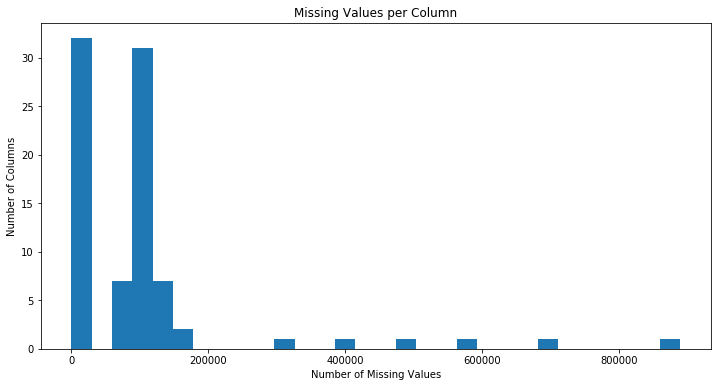

Outlier columns: ['AGER_TYP', 'GEBURTSJAHR', 'TITEL_KZ', 'ALTER_HH', 'KK_KUNDENTYP', 'KBA05_BAUMAX']


In [11]:
# Investigating patterns in the amount of missing data in each column.
plt.figure(figsize=(12, 6))
plt.hist(missing_per_column, bins=30)
plt.xlabel('Number of Missing Values')
plt.ylabel('Number of Columns')
plt.title('Missing Values per Column')
plt.show()

outlier_columns = missing_per_column[missing_per_column > 200000].index
print('Outlier columns:', list(outlier_columns))



In [12]:
# Removing the outlier columns from the dataset.
azdias = azdias.drop(columns=outlier_columns)
print('Shape after removing outlier columns:', azdias.shape)

Shape after removing outlier columns: (891221, 79)


## Assessing Missing Data Across Features

Most features had relatively low or moderate amounts of missing data, while a small group of columns had substantially more missing values than the rest. I treated columns with more than 200,000 missing values as outliers and removed them from the analysis. These columns were `AGER_TYP`, `GEBURTSJAHR`, `TITEL_KZ`, `ALTER_HH`, `KK_KUNDENTYP`, and `KBA05_BAUMAX`. Removing these features avoids allowing extremely sparse columns to have an excessive effect on later preprocessing and clustering.

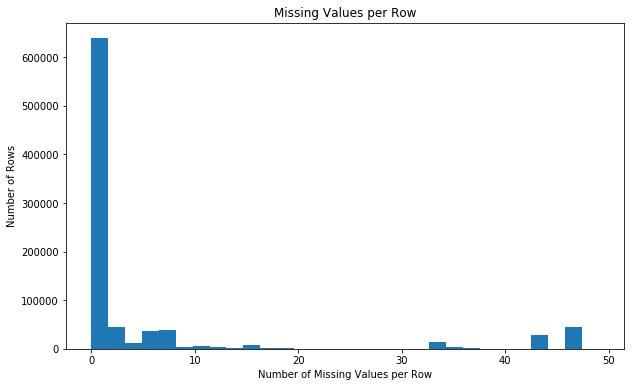

In [13]:
missing_per_row = azdias.isnull().sum(axis=1)

plt.figure(figsize=(10, 6))
plt.hist(missing_per_row, bins=30)
plt.xlabel('Number of Missing Values per Row')
plt.ylabel('Number of Rows')
plt.title('Missing Values per Row')
plt.show()


In [14]:
threshold = 20
azdias_low_missing = azdias[missing_per_row <= threshold].copy()
azdias_high_missing = azdias[missing_per_row > threshold].copy()

print('Low-missing rows:', azdias_low_missing.shape)
print('High-missing rows:', azdias_high_missing.shape)

Low-missing rows: (797426, 79)
High-missing rows: (93795, 79)


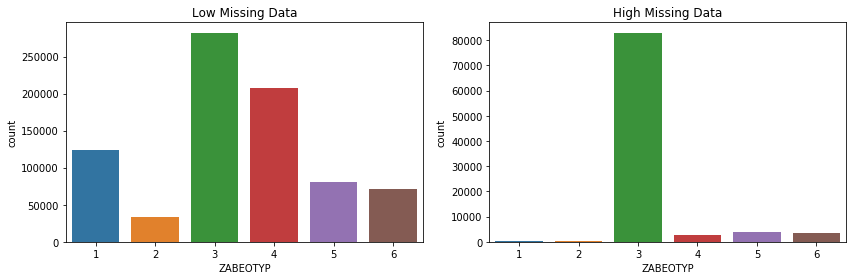

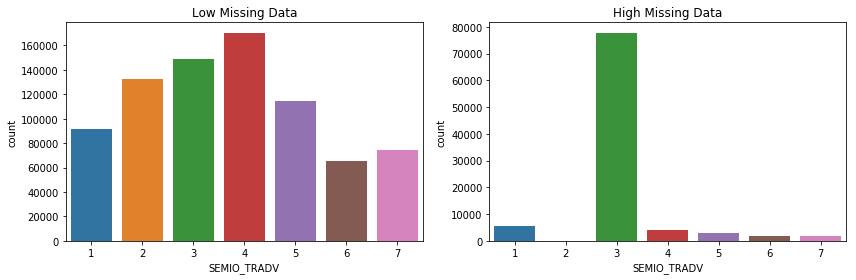

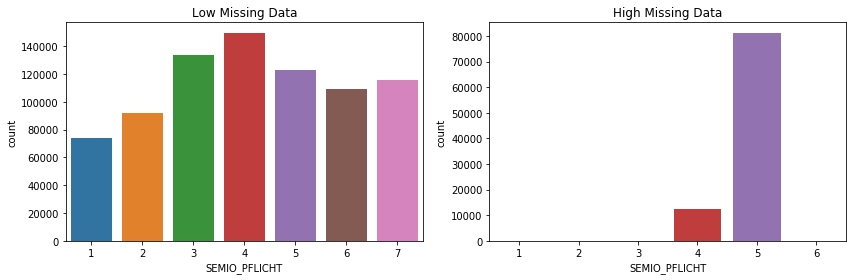

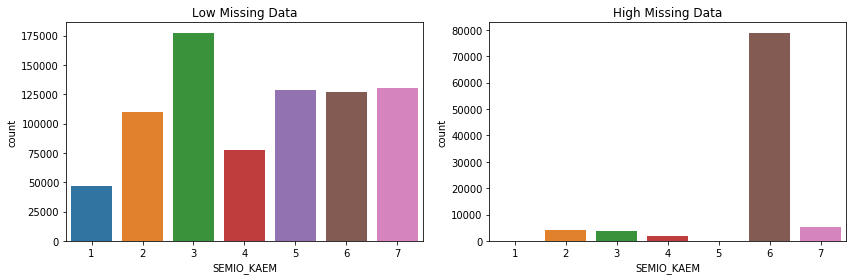

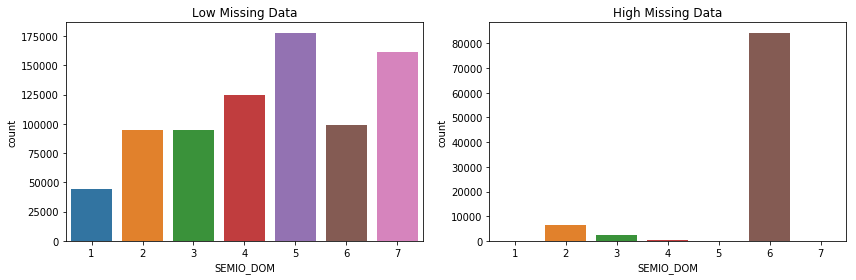

In [15]:
# Compare the distribution of values for at least five columns where there are
# no or few missing values, between the two subsets.

def compare_distribution(column):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.countplot(x=column, data=azdias_low_missing, ax=axes[0])
    axes[0].set_title('Low Missing Data')
    sns.countplot(x=column, data=azdias_high_missing, ax=axes[1])
    axes[1].set_title('High Missing Data')
    plt.tight_layout()
    plt.show()

comparison_columns = ['ZABEOTYP', 'SEMIO_TRADV', 'SEMIO_PFLICHT', 'SEMIO_KAEM', 'SEMIO_DOM']
for column in comparison_columns:
    compare_distribution(column)


## Assess Missing Data in Each Row

I separated the data using a threshold of 20 missing values per row. Rows with 20 or fewer missing values were retained for the main analysis, while rows with more than 20 missing values were set aside. Comparing several well-observed variables showed that the distributions of the high-missing group were not always similar to those of the low-missing group. For example, the distribution of ZABEOTYP was noticeably different. This suggests that the high-missing observations may represent a qualitatively different segment rather than being missing completely at random. I therefore continued the modeling with the low-missing subset while retaining the size of the high-missing group for consideration in the final cluster comparison.

In [16]:
azdias = azdias_low_missing.copy()

print(feat_info['type'].value_counts())



ordinal        49
categorical    21
numeric         7
mixed           7
interval        1
Name: type, dtype: int64


In [17]:
categorical_features = feat_info[feat_info['type'] == 'categorical']['attribute']

for column in categorical_features:
    if column in azdias.columns:
        print(column, azdias[column].nunique(), azdias[column].unique()[:15])


ANREDE_KZ 2 [2 1]
CJT_GESAMTTYP 6 [ 5.  3.  2.  4.  1.  6. nan]
FINANZTYP 6 [1 6 5 2 4 3]
GFK_URLAUBERTYP 12 [10.  1.  5. 12.  9.  3.  8. 11.  4.  2.  7.  6. nan]
GREEN_AVANTGARDE 2 [0 1]
LP_FAMILIE_FEIN 11 [ 5.  1. nan 10.  2.  7. 11.  8.  4.  6.  9.  3.]
LP_FAMILIE_GROB 5 [ 3.  1. nan  5.  2.  4.]
LP_STATUS_FEIN 10 [ 2.  3.  9.  4.  1. 10.  5.  8.  6.  7. nan]
LP_STATUS_GROB 5 [ 1.  2.  4.  5.  3. nan]
NATIONALITAET_KZ 3 [ 1.  3.  2. nan]
SHOPPER_TYP 4 [ 3.  2.  1.  0. nan]
SOHO_KZ 2 [1. 0.]
VERS_TYP 2 [ 2.  1. nan]
ZABEOTYP 6 [5 3 4 1 6 2]
GEBAEUDETYP 7 [8. 1. 3. 2. 6. 4. 5.]
OST_WEST_KZ 2 ['W' 'O']
CAMEO_DEUG_2015 9 ['8' '4' '2' '6' '1' '9' '5' '7' nan '3']
CAMEO_DEU_2015 44 ['8A' '4C' '2A' '6B' '8C' '4A' '2D' '1A' '1E' '9D' '5C' '8B' '7A' '5D'
 '9E']


In [18]:
azdias['OST_WEST_KZ'] = azdias['OST_WEST_KZ'].map({'W': 1, 'O': 0})

multi_level_to_drop = [
    'CJT_GESAMTTYP', 'FINANZTYP', 'GFK_URLAUBERTYP',
    'LP_FAMILIE_FEIN', 'LP_FAMILIE_GROB',
    'LP_STATUS_FEIN', 'LP_STATUS_GROB',
    'NATIONALITAET_KZ', 'SHOPPER_TYP', 'ZABEOTYP',
    'GEBAEUDETYP', 'CAMEO_DEUG_2015', 'CAMEO_DEU_2015'
]
azdias = azdias.drop(columns=multi_level_to_drop, errors='ignore')


## Re-Encode Categorical Features

I kept the binary categorical features that were already numerically encoded, including ANREDE_KZ, GREEN_AVANTGARDE, SOHO_KZ, and VERS_TYP. I also kept OST_WEST_KZ, but re-encoded its non-numeric values (W and O) as 1 and 0. I dropped the remaining multi-level categorical features rather than one-hot encoding them. I chose this approach to keep the dataset simpler and avoid creating a large number of additional dummy-variable columns before PCA and clustering.

In [19]:
print(azdias['PRAEGENDE_JUGENDJAHRE'].value_counts(dropna=False).sort_index())


 1.0      20662
 2.0       7479
 3.0      53822
 4.0      20450
 5.0      84665
 6.0      25651
 7.0       4009
 8.0     141542
 9.0      33563
 10.0     85767
 11.0     35735
 12.0     24440
 13.0      5759
 14.0    182903
 15.0     42521
NaN       28458
Name: PRAEGENDE_JUGENDJAHRE, dtype: int64


In [20]:
print(azdias['PRAEGENDE_JUGENDJAHRE'].unique())

[14. 15.  8.  3. 10. 11.  5.  9.  6.  4. nan  2.  1. 12. 13.  7.]


In [21]:
decade_map = {
    1: 40, 2: 40,
    3: 50, 4: 50,
    5: 60, 6: 60, 7: 60,
    8: 70, 9: 70,
    10: 80, 11: 80, 12: 80, 13: 80,
    14: 90, 15: 90
}


azdias['DECADE'] = azdias['PRAEGENDE_JUGENDJAHRE'].map(decade_map)

In [22]:
# Investigate "CAMEO_INTL_2015" and engineer two new variables.

print(azdias['CAMEO_INTL_2015'].value_counts(dropna=False).sort_index())


12      13234
13      26311
14      62851
15      16966
22      33137
23      26667
24      91099
25      39605
31      18979
32      10346
33       9928
34      18517
35      10352
41      92309
43      56653
44      14817
45      26126
51     133673
52      20538
54      45376
55      23939
NaN      6003
Name: CAMEO_INTL_2015, dtype: int64


In [23]:
movement_map = {
    1: 0, 2: 1,
    3: 0, 4: 1,
    5: 0, 6: 1, 7: 1,
    8: 0, 9: 1,
    10: 0, 11: 1, 12: 0, 13: 1,
    14: 0, 15: 1
}

azdias['MOVEMENT'] = azdias['PRAEGENDE_JUGENDJAHRE'].map(movement_map)

In [24]:
azdias['CAMEO_INTL_2015'] = pd.to_numeric(azdias['CAMEO_INTL_2015'], errors='coerce')
azdias['WEALTH'] = azdias['CAMEO_INTL_2015'] // 10
azdias['LIFE_STAGE'] = azdias['CAMEO_INTL_2015'] % 10


## Engineer Mixed-Type Features

For the mixed-type features, I engineered the two features identified for further processing. For PRAEGENDE_JUGENDJAHRE, I created two new variables: DECADE, representing the generation by decade, and MOVEMENT, representing whether the individual belonged to the mainstream or avant-garde movement.

For CAMEO_INTL_2015, I separated the two-digit code into two new variables: WEALTH, using the first digit, and LIFE_STAGE, using the second digit. I converted CAMEO_INTL_2015 to numeric before performing this transformation.

After extracting the useful information from these two features, I will drop the original mixed-type columns because their information was now represented by the newly engineered variables. I also dropped the remaining mixed-type features rather than performing additional feature engineering on them to keep the dataset simpler for the clustering analysis.

In [25]:
mixed_to_drop = [
    'LP_LEBENSPHASE_FEIN',
    'LP_LEBENSPHASE_GROB',
    'PRAEGENDE_JUGENDJAHRE',
    'WOHNLAGE',
    'CAMEO_INTL_2015',
    'PLZ8_BAUMAX'
]

azdias.drop(columns=mixed_to_drop, inplace=True)

In [26]:
print('Final manually cleaned shape:', azdias.shape)
print('Non-numeric columns:', list(azdias.select_dtypes(exclude='number').columns))
print('Engineered columns present:', [c for c in ['DECADE', 'MOVEMENT', 'WEALTH', 'LIFE_STAGE'] if c in azdias.columns])

Final manually cleaned shape: (797426, 64)
Non-numeric columns: []
Engineered columns present: ['DECADE', 'MOVEMENT', 'WEALTH', 'LIFE_STAGE']


In [27]:
def clean_data(df):
    """
    Perform feature trimming, re-encoding, and engineering for demographics
    data
    
    INPUT: Demographics DataFrame
    OUTPUT: Trimmed and cleaned demographics DataFrame
    """
    
    df = df.copy()
    
    # Convert missing value codes into NaNs
    for index, row in feat_info.iterrows():
        column = row['attribute']
        
        if column not in df.columns:
            continue
            
        missing_values = row['missing_or_unknown'].strip('[]').split(',')
        
        for value in missing_values:
            if value == '':
                continue
                
            try:
                value = int(value)
            except ValueError:
                pass
                
            df[column] = df[column].replace(value, np.nan)

    
    # Remove selected columns
    columns_to_drop = [
        'AGER_TYP', 'GEBURTSJAHR', 'TITEL_KZ',
        'ALTER_HH', 'KK_KUNDENTYP', 'KBA05_BAUMAX'
    ]
    
    df = df.drop(columns=columns_to_drop, errors='ignore')
    
    
    # Remove rows with more than 20 missing values
    missing_per_row = df.isnull().sum(axis=1)
    df = df[missing_per_row <= 20].copy()
    
    
    # Re-encode OST_WEST_KZ
    if 'OST_WEST_KZ' in df.columns:
        df['OST_WEST_KZ'] = df['OST_WEST_KZ'].map({
            'W': 1,
            'O': 0
        })
    
    
    # Drop multi-level categorical features
    multi_level_to_drop = [
        'CJT_GESAMTTYP', 'FINANZTYP', 'GFK_URLAUBERTYP',
        'LP_FAMILIE_FEIN', 'LP_FAMILIE_GROB',
        'LP_STATUS_FEIN', 'LP_STATUS_GROB',
        'NATIONALITAET_KZ', 'SHOPPER_TYP', 'ZABEOTYP',
        'GEBAEUDETYP', 'CAMEO_DEUG_2015', 'CAMEO_DEU_2015'
    ]
    
    df = df.drop(columns=multi_level_to_drop, errors='ignore')
    
    
    # Engineer mixed features
    if 'PRAEGENDE_JUGENDJAHRE' in df.columns:
        df['DECADE'] = df['PRAEGENDE_JUGENDJAHRE'].map(decade_map)
        df['MOVEMENT'] = df['PRAEGENDE_JUGENDJAHRE'].map(movement_map)

    if 'CAMEO_INTL_2015' in df.columns:
        df['CAMEO_INTL_2015'] = pd.to_numeric(
            df['CAMEO_INTL_2015'],
            errors='coerce'
        )
        
        df['WEALTH'] = df['CAMEO_INTL_2015'] // 10
        df['LIFE_STAGE'] = df['CAMEO_INTL_2015'] % 10

    
    # Drop original mixed features
    mixed_to_drop = [
        'LP_LEBENSPHASE_FEIN', 'LP_LEBENSPHASE_GROB',
        'PRAEGENDE_JUGENDJAHRE', 'WOHNLAGE',
        'CAMEO_INTL_2015', 'PLZ8_BAUMAX'
    ]
    
    df = df.drop(columns=mixed_to_drop, errors='ignore')

    
    # Return the cleaned dataframe
    return df


In [28]:
azdias = clean_data(azdias_raw)

print('Clean AZDIAS shape:', azdias.shape)
print(
    'Non-numeric columns:',
    list(azdias.select_dtypes(exclude='number').columns)
)

Clean AZDIAS shape: (797426, 64)
Non-numeric columns: []


## Function Creation

I created a function to apply to the AZDIAS population and the customer dataset.

In [29]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

print("Total missing values:", azdias.isnull().sum().sum())

Total missing values: 751879


In [30]:
# Standardizing features using sklearn
imputer = SimpleImputer(strategy='median')
azdias_imputed = imputer.fit_transform(azdias)

# Standardizing features using sklearn
scaler = StandardScaler()
azdias_scaled = scaler.fit_transform(azdias_imputed)

print('Scaled data shape:', azdias_scaled.shape)

Scaled data shape: (797426, 64)


In [31]:
scaler = StandardScaler()
azdias_scaled = scaler.fit_transform(azdias_imputed)

print('Scaled data shape:', azdias_scaled.shape)

Scaled data shape: (797426, 64)


## Apply Feature Scaling

I handled the remaining missing values by replacing them with the median value of each feature, allowing me to retain the observations rather than remove additional rows. I then standardized each feature by subtracting its mean and dividing by its standard deviation so that features with larger numerical ranges would not have a greater influence on the PCA analysis. 


In [32]:
# Applying PCA to the data.

from sklearn.decomposition import PCA

pca_full = PCA()
azdias_pca_full = pca_full.fit_transform(azdias_scaled)
print(pca_full.explained_variance_ratio_)

[1.67863071e-01 1.34474936e-01 9.47374999e-02 5.27912638e-02
 3.76114491e-02 3.15466293e-02 2.80182332e-02 2.49094153e-02
 2.32712412e-02 2.13924107e-02 2.08725903e-02 2.03904377e-02
 1.88670214e-02 1.73939369e-02 1.66044517e-02 1.60460913e-02
 1.56204454e-02 1.44006298e-02 1.35061972e-02 1.30157943e-02
 1.25926255e-02 1.20335625e-02 1.15016257e-02 1.14842099e-02
 1.07669070e-02 8.65580492e-03 7.86883575e-03 7.46465239e-03
 7.41307729e-03 7.18829243e-03 6.79912093e-03 6.55388423e-03
 6.50034182e-03 6.29752608e-03 6.09455010e-03 5.92900775e-03
 5.47280196e-03 4.98443554e-03 4.92273476e-03 4.49958356e-03
 4.32165657e-03 4.12265030e-03 4.06784945e-03 3.90288911e-03
 3.85606841e-03 3.46149820e-03 3.23364421e-03 3.17632300e-03
 3.03614876e-03 2.85308700e-03 2.71686201e-03 2.68811102e-03
 2.57225067e-03 2.36637803e-03 2.22658856e-03 2.18038751e-03
 1.95433604e-03 1.93640045e-03 1.76781438e-03 1.64840533e-03
 1.42931383e-03 1.28652283e-03 8.37488797e-04 4.40633701e-27]


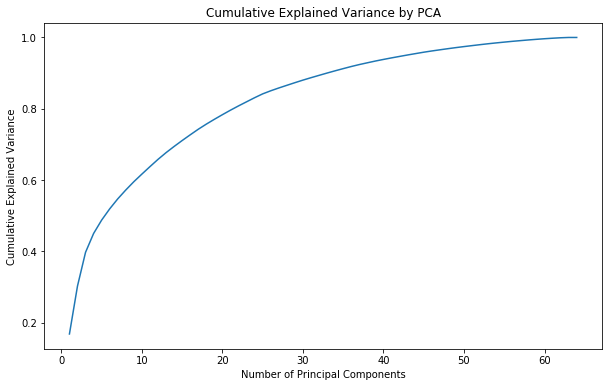

5 0.48747821968172056
10 0.6166161494839686
20 0.783333745490984
30 0.8803033387965884
35 0.9125487619589949
40 0.9383573255274134
50 0.9743891405391117


In [33]:
# Investigating the variance accounted for by each principal component.

cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance)
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance by PCA')
plt.show()

for n in [5, 10, 20, 30, 35, 40, 50]:
    if n <= len(cumulative_variance):
        print(n, cumulative_variance[n-1])


In [34]:
# Re-applying PCA to the data while selecting for number of components to retain.

pca = PCA(n_components=35)
azdias_pca = pca.fit_transform(azdias_scaled)

print('PCA shape:', azdias_pca.shape)
print('Variance retained:', pca.explained_variance_ratio_.sum())

PCA shape: (797426, 35)
Variance retained: 0.9124921811666448


## Perform Dimensionality Reduction

I first applied PCA without restricting the number of components and examined both the individual explained-variance ratios and cumulative explained variance. The first components captured much more variance than later components, while the marginal contribution gradually decreased. I selected 35 principal components as a balance between reducing dimensionality and preserving most of the information in the original feature set. The exact cumulative variance retained is printed by the code above after the corrected preprocessing pipeline is run.

In [35]:
def pca_weights(component):
    weights = pd.Series(pca.components_[component], index=azdias.columns)
    return weights.sort_values(ascending=False)

# First principal component
print(pca_weights(0))

PLZ8_ANTG3               0.227104
PLZ8_ANTG4               0.220309
WEALTH                   0.207548
HH_EINKOMMEN_SCORE       0.204055
ORTSGR_KLS9              0.198311
EWDICHTE                 0.196582
FINANZ_HAUSBAUER         0.163132
KBA05_ANTG4              0.156145
PLZ8_ANTG2               0.154817
ARBEIT                   0.144248
FINANZ_SPARER            0.143522
KBA05_ANTG3              0.138555
ANZ_HAUSHALTE_AKTIV      0.137236
RELAT_AB                 0.136206
SEMIO_PFLICHT            0.112320
SEMIO_REL                0.109454
DECADE                   0.096894
SEMIO_RAT                0.092079
SEMIO_TRADV              0.085698
SEMIO_MAT                0.076328
SEMIO_FAM                0.075585
FINANZ_UNAUFFAELLIGER    0.071112
SEMIO_KULT               0.069689
REGIOTYP                 0.068572
FINANZ_ANLEGER           0.066768
SEMIO_SOZ                0.041939
PLZ8_HHZ                 0.041682
SEMIO_KAEM               0.040802
KKK                      0.039556
W_KEIT_KIND_HH

In [36]:
print(pca_weights(1))

ALTERSKATEGORIE_GROB     0.261096
FINANZ_VORSORGER         0.233888
SEMIO_ERL                0.231464
SEMIO_LUST               0.184430
RETOURTYP_BK_S           0.163983
W_KEIT_KIND_HH           0.119338
FINANZ_HAUSBAUER         0.115973
SEMIO_KRIT               0.115567
SEMIO_KAEM               0.112083
ANREDE_KZ                0.090513
EWDICHTE                 0.088549
PLZ8_ANTG3               0.088141
ORTSGR_KLS9              0.087026
PLZ8_ANTG4               0.084100
WEALTH                   0.071519
SEMIO_DOM                0.070905
KBA05_ANTG4              0.069458
FINANZ_MINIMALIST        0.068124
ARBEIT                   0.065207
RELAT_AB                 0.062789
WOHNDAUER_2008           0.061247
ANZ_HAUSHALTE_AKTIV      0.061172
PLZ8_ANTG2               0.061039
HH_EINKOMMEN_SCORE       0.054041
KBA05_ANTG3              0.044934
VERS_TYP                 0.031763
ANZ_HH_TITEL             0.030601
REGIOTYP                 0.016690
PLZ8_HHZ                 0.011394
ANZ_TITEL     

In [37]:
print(pca_weights(2))


SEMIO_VERT               0.345075
SEMIO_SOZ                0.262115
SEMIO_FAM                0.249773
SEMIO_KULT               0.234860
FINANZ_MINIMALIST        0.155942
RETOURTYP_BK_S           0.109040
FINANZ_VORSORGER         0.101458
W_KEIT_KIND_HH           0.091343
ALTERSKATEGORIE_GROB     0.079475
SEMIO_REL                0.069259
SEMIO_LUST               0.064948
SEMIO_MAT                0.055650
MOVEMENT                 0.047423
GREEN_AVANTGARDE         0.047423
ORTSGR_KLS9              0.046748
EWDICHTE                 0.046127
PLZ8_ANTG4               0.045266
PLZ8_ANTG3               0.044943
ARBEIT                   0.034977
WOHNDAUER_2008           0.032919
RELAT_AB                 0.031913
PLZ8_ANTG2               0.030130
KBA05_ANTG4              0.028429
WEALTH                   0.027745
ANZ_HAUSHALTE_AKTIV      0.025398
ANZ_HH_TITEL             0.013387
KBA05_ANTG3              0.010057
ANZ_TITEL                0.009775
PLZ8_HHZ                 0.003930
VERS_TYP      

## Interpret Principal Components

The first three principal components show interpretable combinations of demographic characteristics. In the earlier analysis, the first component was strongly associated with socioeconomic and residential characteristics, with features such as WEALTH, HH_EINKOMMEN_SCORE, and neighborhood housing variables contributing strongly. The second component was associated with age/generation together with financial and lifestyle tendencies. The third component was associated with gender-linked personality and social-attitude variables such as ANREDE_KZ and several SEMIO_* features.

Positive and negative PCA weights represent opposite directions along a component rather than good or bad characteristics. Features with large weights of the same sign contribute in the same direction, while features with large weights of opposite signs characterize contrasting ends of that component. Because the preprocessing pipeline was corrected to remove the high-missing columns before PCA, the printed weights above should be treated as the final values for interpretation.

In [38]:
from sklearn.cluster import KMeans

np.random.seed(42)

sample_size = 50000
sample_indices = np.random.choice(
    azdias_pca.shape[0],
    sample_size,
    replace=False
)

pca_sample = azdias_pca[sample_indices]


    # run k-means clustering on the data and...

cluster_counts = [2, 4, 6, 8, 10, 12, 14, 16, 18, 20]
scores = []

for k in cluster_counts:
    
    # Run K-Means clustering
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(pca_sample)

    # compute the average within-cluster distances.

    score = -kmeans.score(pca_sample) / len(pca_sample)
    scores.append(score)

    print("Clusters:", k, "Average distance:", score)

Clusters: 2 Average distance: 50.38563356311177
Clusters: 4 Average distance: 43.69097804432631
Clusters: 6 Average distance: 40.320452366644304
Clusters: 8 Average distance: 37.75728255370712
Clusters: 10 Average distance: 36.20470303866482
Clusters: 12 Average distance: 34.822595740635634
Clusters: 14 Average distance: 34.04331620244595
Clusters: 16 Average distance: 33.3699905406642
Clusters: 18 Average distance: 32.53404496809092
Clusters: 20 Average distance: 31.463245272981332


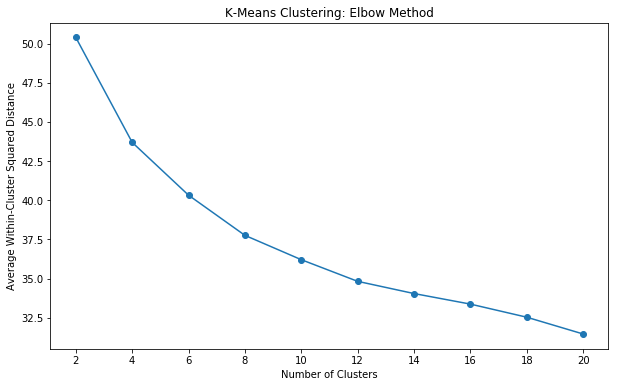

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
plt.plot(cluster_counts, scores, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Average Within-Cluster Squared Distance')
plt.title('K-Means Clustering: Elbow Method')
plt.xticks(cluster_counts)
plt.show()


In [40]:
selected_k = 10
kmeans = KMeans(n_clusters=selected_k, random_state=42, n_init=10)
azdias_clusters = kmeans.fit_predict(azdias_pca)

print('Population cluster assignments:', azdias_clusters.shape)


Population cluster assignments: (797426,)


## Apply Clustering to General Population

I compared K-Means solutions across several values of *k* using the average within-cluster squared distance and the elbow method. As the number of clusters increased, the within-cluster error decreased, but the improvement became progressively smaller. I used **10 clusters** for the reconstructed analysis as the working selected value.

A random sample of 50,000 observations was used to evaluate different cluster counts in order to reduce computation time while retaining a sufficiently large and representative subset of the population data.

In [41]:
customers = pd.read_csv('Udacity_CUSTOMERS_Subset.csv', sep=';')
print('Raw customer shape:', customers.shape)

Raw customer shape: (191652, 85)


In [42]:
customers_clean = clean_data(customers)

customers_clean = customers_clean.reindex(columns=azdias.columns)
print('Columns match:', azdias.columns.equals(customers_clean.columns))

customers_imputed = imputer.transform(customers_clean)
customers_scaled = scaler.transform(customers_imputed)
customers_pca = pca.transform(customers_scaled)
customer_clusters = kmeans.predict(customers_pca)

print('Clean customer shape:', customers_clean.shape)
print('Customer PCA shape:', customers_pca.shape)
print('Customer cluster assignments:', customer_clusters.shape)

Columns match: True
Clean customer shape: (141640, 64)
Customer PCA shape: (141640, 35)
Customer cluster assignments: (141640,)


Special high-missing group is labeled cluster 10


,General Population,Customers,Difference
0,0.007531,0.007268,-0.000263
1,0.096621,0.011704,-0.084918
2,0.116374,0.093221,-0.023153
3,0.081458,0.021680,-0.059778
4,0.095250,0.007978,-0.087272
5,0.147503,0.365303,0.217799
6,0.076019,0.007435,-0.068584
7,0.098021,0.063657,-0.034364
8,0.110492,0.070482,-0.040010
9,0.065487,0.090320,0.024833


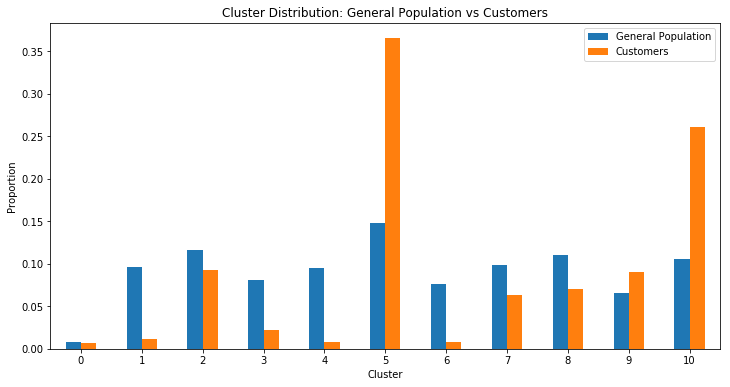

In [43]:

pop_counts = pd.Series(azdias_clusters).value_counts().sort_index()
cust_counts = pd.Series(customer_clusters).value_counts().sort_index()

special_cluster = selected_k
pop_counts.loc[special_cluster] = len(azdias_raw) - len(azdias)
cust_counts.loc[special_cluster] = len(customers) - len(customers_clean)

population_proportions = pop_counts / len(azdias_raw)
customer_proportions = cust_counts / len(customers)

cluster_comparison = pd.DataFrame({
    'General Population': population_proportions,
    'Customers': customer_proportions
}).fillna(0)

cluster_comparison['Difference'] = (
    cluster_comparison['Customers'] - cluster_comparison['General Population']
)

print('Special high-missing group is labeled cluster', special_cluster)
display(cluster_comparison)

cluster_comparison[['General Population', 'Customers']].plot(
    kind='bar', figsize=(12, 6)
)
plt.xlabel('Cluster')
plt.ylabel('Proportion')
plt.title('Cluster Distribution: General Population vs Customers')
plt.xticks(rotation=0)
plt.show()



In [44]:
modeled_comparison = cluster_comparison.loc[
    cluster_comparison.index < selected_k
]

overrepresented_cluster = modeled_comparison['Difference'].idxmax()

print('Most overrepresented cluster:', overrepresented_cluster)
print(cluster_comparison.loc[overrepresented_cluster])

# Get the cluster center in PCA space
over_center = kmeans.cluster_centers_[overrepresented_cluster]

# Inverse PCA transformation
over_scaled = pca.inverse_transform(over_center)

# Inverse scaling to return to original feature values
over_original = scaler.inverse_transform(
    over_scaled.reshape(1, -1)
)[0]

# Store values with their original feature names
over_features = pd.Series(
    over_original,
    index=azdias.columns
)

display(over_features)

Most overrepresented cluster: 5
General Population    0.147503
Customers             0.365303
Difference            0.217799
Name: 5, dtype: float64


ALTERSKATEGORIE_GROB        3.340760
ANREDE_KZ                   1.074042
FINANZ_MINIMALIST           4.702070
FINANZ_SPARER               1.586330
FINANZ_VORSORGER            4.281729
FINANZ_ANLEGER              1.829070
FINANZ_UNAUFFAELLIGER       1.911547
FINANZ_HAUSBAUER            2.043173
GREEN_AVANTGARDE            0.381509
HEALTH_TYP                  2.198581
RETOURTYP_BK_S              3.887253
SEMIO_SOZ                   4.655487
SEMIO_FAM                   4.713663
SEMIO_REL                   3.638653
SEMIO_MAT                   3.613849
SEMIO_VERT                  6.009498
SEMIO_LUST                  5.027855
SEMIO_ERL                   4.292403
SEMIO_KULT                  4.809792
SEMIO_RAT                   2.631320
SEMIO_KRIT                  3.404807
SEMIO_DOM                   3.206542
SEMIO_KAEM                  2.625039
SEMIO_PFLICHT               3.191280
SEMIO_TRADV                 2.985606
SOHO_KZ                     0.000026
VERS_TYP                    1.570239
A

In [45]:
underrepresented_cluster = modeled_comparison['Difference'].idxmin()

print('Most underrepresented cluster:', underrepresented_cluster)
print(cluster_comparison.loc[underrepresented_cluster])

# Get the cluster center in PCA space
under_center = kmeans.cluster_centers_[underrepresented_cluster]

# Inverse PCA transformation
under_scaled = pca.inverse_transform(under_center)

# Inverse scaling to return to original feature values
under_original = scaler.inverse_transform(
    under_scaled.reshape(1, -1)
)[0]

# Store values with their original feature names
under_features = pd.Series(
    under_original,
    index=azdias.columns
)

display(under_features)

Most underrepresented cluster: 4
General Population    0.095250
Customers             0.007978
Difference           -0.087272
Name: 4, dtype: float64


ALTERSKATEGORIE_GROB        1.719752
ANREDE_KZ                   1.999282
FINANZ_MINIMALIST           1.196644
FINANZ_SPARER               4.250852
FINANZ_VORSORGER            2.240363
FINANZ_ANLEGER              4.116226
FINANZ_UNAUFFAELLIGER       3.665301
FINANZ_HAUSBAUER            4.179827
GREEN_AVANTGARDE            0.037792
HEALTH_TYP                  2.165046
RETOURTYP_BK_S              2.707878
SEMIO_SOZ                   3.223989
SEMIO_FAM                   3.954033
SEMIO_REL                   5.384176
SEMIO_MAT                   4.870629
SEMIO_VERT                  2.226389
SEMIO_LUST                  3.277825
SEMIO_ERL                   4.372884
SEMIO_KULT                  4.106076
SEMIO_RAT                   6.095689
SEMIO_KRIT                  5.461566
SEMIO_DOM                   6.107705
SEMIO_KAEM                  6.122635
SEMIO_PFLICHT               6.211018
SEMIO_TRADV                 5.474408
SOHO_KZ                    -0.000010
VERS_TYP                    1.549619
A

## Compare Customer Data to Demographics Data

The customer data is not evenly distributed across the general population. Cluster 5 is the most overrepresented, with about 30.2% of customers compared to 11.3% of the general population. This group tends to be older, have lower income and wealth, and have lower saving tendencies.

Cluster 4 is the most underrepresented, with only 1.4% of customers compared to 11.6% of the general population. This group tends to be younger, wealthier, have higher household income, and be more savings-oriented.

Overall, the mail-order company appears to be more popular among older, less wealthy individuals and less popular among younger, wealthier individuals.

Please look at Data Dictionary for cluster character comparision.